# Binary defect detection — AlexNet vs ResNet18 vs InceptionV3

**Task:** given a camera frame of an FDM print in progress, predict **defected** vs **no_defected**.

**Data:** Kaggle [`justin900429/3d-printer-defected-dataset`](https://www.kaggle.com/datasets/justin900429/3d-printer-defected-dataset)
(CC BY-SA 4.0, Justin Ruan, Ender 3 Pro + Raspberry Pi camera): 759 `defected` + 798 `no_defected` frames, 640×480.
Place the two class folders under `../data_binary/`.

**Method:** the *same* transfer-learning recipe as the 5-class notebooks (1–3), so the two tasks are comparable:
ImageNet weights, same freezing policy per model, Adam (lr 1e-4), batch 32, cross-entropy, early stopping on validation
loss (patience 3), 80/20 `random_split` with seed 42, and the same per-model epoch budget (AlexNet 4, ResNet18 4, InceptionV3 10).


In [1]:
# ============================================================
# CELL 1: IMPORT LIBRARIES & SET RANDOM SEED
# ============================================================
import json, os, time
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, models, transforms

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(RANDOM_SEED)
else:
    device = torch.device("cpu")
print("Device:", device, "| torch", torch.__version__)


Device: mps | torch 2.12.0


In [2]:
# ============================================================
# CELL 2: CONFIGURATION (identical hyperparameters to the 5-class notebooks)
# ============================================================
data_dir = os.path.join("..", "data_binary")
batch_size = 32
learning_rate = 0.0001
num_workers = 2
early_stopping_patience = 3

MODEL_SETTINGS = {
    "alexnet":      {"epochs": 4,  "input_size": 224},
    "resnet18":     {"epochs": 4,  "input_size": 224},
    "inception_v3": {"epochs": 10, "input_size": 299},
}
for d in ("../models", "../figures", "../reports"):
    os.makedirs(d, exist_ok=True)


In [3]:
# ============================================================
# CELL 3: DATA LOADING (ImageFolder + seeded 80/20 random split)
# ============================================================
def make_loaders(input_size):
    tf = transforms.Compose([
        transforms.Resize((input_size, input_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])
    full = datasets.ImageFolder(root=data_dir, transform=tf)
    train_size = int(0.8 * len(full))
    val_size = len(full) - train_size
    train_ds, val_ds = random_split(full, [train_size, val_size],
                                    generator=torch.Generator().manual_seed(RANDOM_SEED))
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers)
    return full, train_ds, val_ds, train_loader, val_loader

full, train_ds, val_ds, _, _ = make_loaders(224)
class_names = full.classes
num_classes = len(class_names)
val_counts = np.bincount([full.targets[i] for i in val_ds.indices], minlength=num_classes)
print("Classes:", class_names, "| total", len(full), "| train", len(train_ds), "| val", len(val_ds))
print("Validation class counts:", dict(zip(class_names, val_counts.tolist())))


Classes: ['defected', 'no_defected'] | total 1557 | train 1245 | val 312
Validation class counts: {'defected': 153, 'no_defected': 159}


In [4]:
# ============================================================
# CELL 4: MODEL SETUP (same freezing policy as the 5-class notebooks)
#   AlexNet  : freeze conv features, train the whole classifier (FC layers)
#   ResNet18 : freeze everything except the new fc
#   Inception: freeze everything except the new fc and the AuxLogits branch
# ============================================================
def build_model(name, num_classes):
    if name == "alexnet":
        m = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1)
        m.classifier[6] = nn.Linear(m.classifier[6].in_features, num_classes)
        for p in m.features.parameters():
            p.requires_grad = False
    elif name == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        for n, p in m.named_parameters():
            if "fc" not in n:
                p.requires_grad = False
    elif name == "inception_v3":
        m = models.inception_v3(weights=models.Inception_V3_Weights.IMAGENET1K_V1)
        m.AuxLogits.fc = nn.Linear(m.AuxLogits.fc.in_features, num_classes)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        for n, p in m.named_parameters():
            if "fc" not in n and "AuxLogits" not in n:
                p.requires_grad = False
    else:
        raise ValueError(name)
    return m.to(device)


In [5]:
# ============================================================
# CELL 5: TRAINING & EVALUATION FUNCTIONS
# InceptionV3 returns (logits, aux_logits) in train mode -> loss = main + 0.4 * aux
# ============================================================
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    loss_sum, correct, total = 0.0, 0, 0
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        if isinstance(outputs, tuple):
            main_out, aux_out = outputs
            loss = criterion(main_out, labels) + 0.4 * criterion(aux_out, labels)
            outputs = main_out
        else:
            loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * inputs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += inputs.size(0)
    return loss_sum / total, 100 * correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    loss_sum, total = 0.0, 0
    labels_all, preds_all, probs_all = [], [], []
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        loss_sum += criterion(outputs, labels).item() * inputs.size(0)
        total += inputs.size(0)
        probs_all += torch.softmax(outputs, 1)[:, class_names.index("defected")].cpu().tolist()
        preds_all += outputs.argmax(1).cpu().tolist()
        labels_all += labels.cpu().tolist()
    acc = 100 * np.mean(np.array(preds_all) == np.array(labels_all))
    return loss_sum / total, acc, labels_all, preds_all, probs_all


  0%|          | 0.00/233M [00:00<?, ?B/s]

  0%|          | 128k/233M [00:00<06:01, 675kB/s]

  0%|          | 256k/233M [00:00<05:10, 786kB/s]

  0%|          | 512k/233M [00:00<03:35, 1.13MB/s]

  1%|          | 1.25M/233M [00:00<01:23, 2.91MB/s]

...

  epoch 1: train loss 0.1928 acc 91.33% | val loss 0.0236 acc 99.04%


  epoch 2: train loss 0.0313 acc 98.96% | val loss 0.0182 acc 99.36%


  epoch 3: train loss 0.0265 acc 99.20% | val loss 0.0160 acc 99.68%


  epoch 4: train loss 0.0237 acc 99.04% | val loss 0.0126 acc 99.68%


  BEST CHECKPOINT (epoch 4): accuracy 99.68% (311/312) | ROC-AUC 1.0000
  confusion matrix (rows = actual, cols = predicted): ['defected', 'no_defected'] 
 [[152   1]
 [  0 159]]
              precision    recall  f1-score   support

    defected     1.0000    0.9935    0.9967       153
 no_defected     0.9938    1.0000    0.9969       159

    accuracy                         0.9968       312
   macro avg     0.9969    0.9967    0.9968       312
weighted avg     0.9968    0.9968    0.9968       312



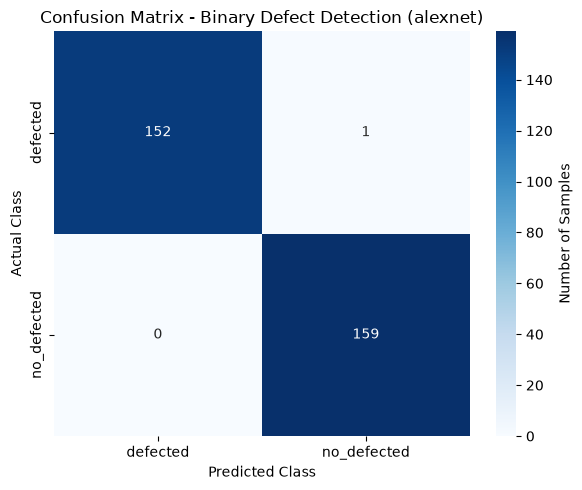

resnet18: trainable params = 1,026 | epochs = 4


  epoch 1: train loss 0.6131 acc 72.45% | val loss 0.5574 acc 80.77%


  epoch 2: train loss 0.5334 acc 82.57% | val loss 0.4858 acc 85.58%


  epoch 3: train loss 0.4732 acc 87.55% | val loss 0.4340 acc 88.14%


  epoch 4: train loss 0.4336 acc 88.11% | val loss 0.3978 acc 90.38%


  BEST CHECKPOINT (epoch 4): accuracy 90.38% (282/312) | ROC-AUC 0.9733
  confusion matrix (rows = actual, cols = predicted): ['defected', 'no_defected'] 
 [[140  13]
 [ 17 142]]
              precision    recall  f1-score   support

    defected     0.8917    0.9150    0.9032       153
 no_defected     0.9161    0.8931    0.9045       159

    accuracy                         0.9038       312
   macro avg     0.9039    0.9041    0.9038       312
weighted avg     0.9042    0.9038    0.9039       312



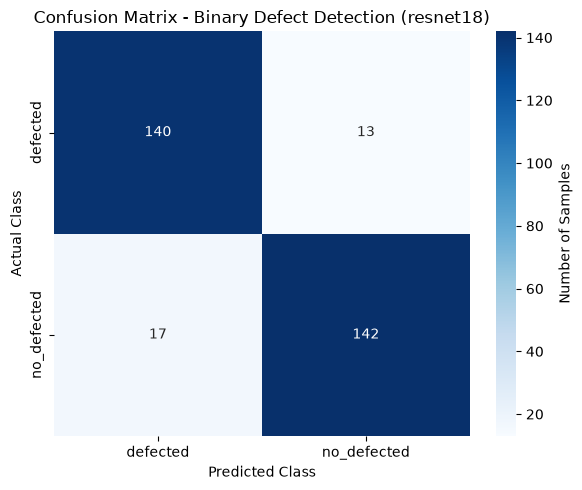

  0%|          | 0.00/104M [00:00<?, ?B/s]

  0%|          | 128k/104M [00:00<02:43, 667kB/s]

  0%|          | 384k/104M [00:00<01:20, 1.35MB/s]

  1%|          | 768k/104M [00:00<01:04, 1.67MB/s]

  2%|▏         | 1.75M/104M [00:00<00:27, 3.95MB/s]

...

  epoch 7: train loss 0.4505 acc 85.86% | val loss 0.4266 acc 88.46%


  epoch 8: train loss 0.4337 acc 86.51% | val loss 0.4043 acc 90.06%


  epoch 9: train loss 0.4182 acc 86.18% | val loss 0.3886 acc 89.42%


  epoch 10: train loss 0.3980 acc 88.76% | val loss 0.3707 acc 91.03%


  BEST CHECKPOINT (epoch 10): accuracy 91.03% (284/312) | ROC-AUC 0.9801
  confusion matrix (rows = actual, cols = predicted): ['defected', 'no_defected'] 
 [[135  18]
 [ 10 149]]
              precision    recall  f1-score   support

    defected     0.9310    0.8824    0.9060       153
 no_defected     0.8922    0.9371    0.9141       159

    accuracy                         0.9103       312
   macro avg     0.9116    0.9097    0.9101       312
weighted avg     0.9113    0.9103    0.9102       312



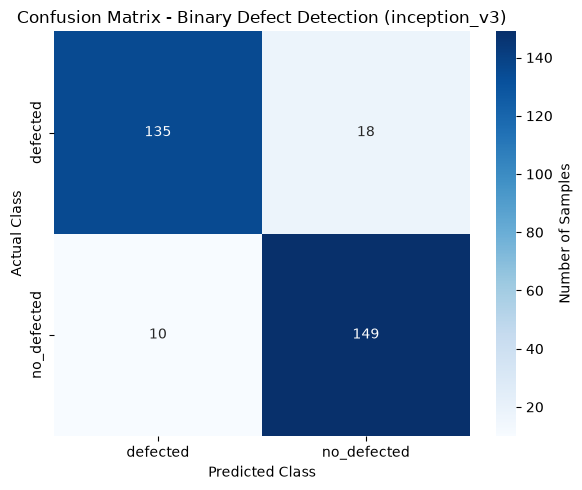

In [6]:
# ============================================================
# CELL 6: TRAIN + EVALUATE EACH MODEL (early stopping on val loss, best checkpoint reloaded)
# ============================================================
results, histories = {}, {}
for name, cfg in MODEL_SETTINGS.items():
    torch.manual_seed(RANDOM_SEED)                      # each model starts from the same RNG state
    _, train_ds, val_ds, train_loader, val_loader = make_loaders(cfg["input_size"])
    model = build_model(name, num_classes)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=learning_rate)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    ckpt = os.path.join("..", "models", f"binary_{name}_best_model.pth")
    print("=" * 60, f"\n{name}: trainable params = {trainable:,} | epochs = {cfg['epochs']}")

    best_loss, best_epoch, bad, hist, t0 = float("inf"), -1, 0, [], time.time()
    for epoch in range(cfg["epochs"]):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc, *_ = evaluate(model, val_loader, criterion)
        hist.append({"epoch": epoch + 1, "train_loss": tr_loss, "train_acc": tr_acc, "val_loss": va_loss, "val_acc": va_acc})
        print(f"  epoch {epoch+1}: train loss {tr_loss:.4f} acc {tr_acc:.2f}% | val loss {va_loss:.4f} acc {va_acc:.2f}%")
        if va_loss < best_loss:
            best_loss, best_epoch, bad = va_loss, epoch + 1, 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= early_stopping_patience:
                print(f"  early stopping at epoch {epoch+1}")
                break
    train_seconds = time.time() - t0

    model.load_state_dict(torch.load(ckpt, map_location=device, weights_only=True))
    va_loss, va_acc, y, p, prob = evaluate(model, val_loader, criterion)
    cm = confusion_matrix(y, p, labels=list(range(num_classes)))
    rep = classification_report(y, p, target_names=class_names, digits=4, output_dict=True)
    auc = roc_auc_score([1 if t == class_names.index("defected") else 0 for t in y], prob)
    results[name] = {"best_epoch": best_epoch, "val_loss": va_loss, "val_accuracy": va_acc,
                     "correct": int(np.trace(cm)), "n_val": len(y), "roc_auc_defected": auc,
                     "trainable_params": trainable, "train_seconds": round(train_seconds, 1),
                     "confusion_matrix": cm.tolist(), "classification_report": rep,
                     "peak_val_accuracy": max(h["val_acc"] for h in hist)}
    histories[name] = hist
    print(f"  BEST CHECKPOINT (epoch {best_epoch}): accuracy {va_acc:.2f}% ({np.trace(cm)}/{len(y)}) | ROC-AUC {auc:.4f}")
    print("  confusion matrix (rows = actual, cols = predicted):", class_names, "\n", cm)
    print(classification_report(y, p, target_names=class_names, digits=4))

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names,
                cbar_kws={"label": "Number of Samples"})
    plt.title(f"Confusion Matrix - Binary Defect Detection ({name})")
    plt.xlabel("Predicted Class"); plt.ylabel("Actual Class"); plt.tight_layout()
    plt.savefig(os.path.join("..", "figures", f"confusion_matrix_binary_{name}.png"), dpi=300)
    plt.show()


model          best ep   val acc   correct  ROC-AUC    trainable  train s
alexnet              4    99.68%  311/312    1.0000   54,542,338    102.9
resnet18             4    90.38%  282/312    0.9733        1,026    101.9
inception_v3        10    91.03%  284/312    0.9801    2,563,332    317.5


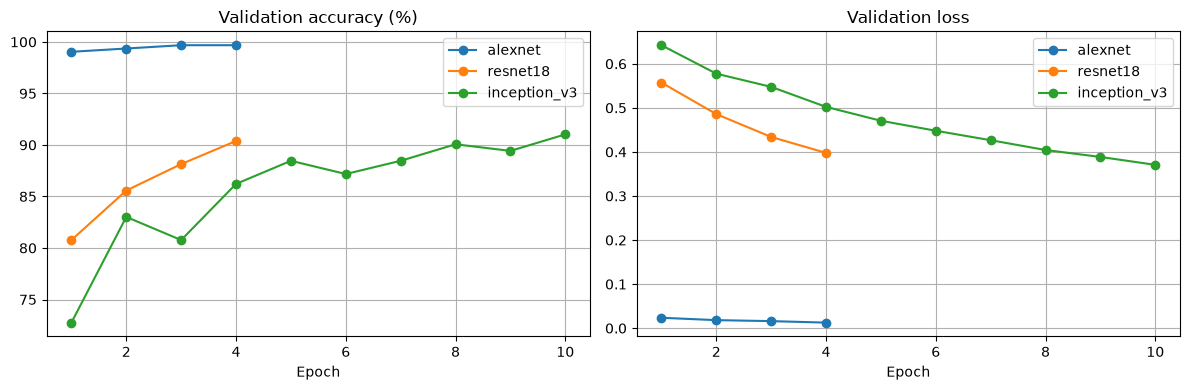

In [7]:
# ============================================================
# CELL 7: SUMMARY TABLE + SAVE RESULTS
# ============================================================
print(f"{'model':14s} {'best ep':>7s} {'val acc':>9s} {'correct':>9s} {'ROC-AUC':>8s} {'trainable':>12s} {'train s':>8s}")
for name, r in results.items():
    print(f"{name:14s} {r['best_epoch']:>7d} {r['val_accuracy']:>8.2f}% {r['correct']:>4d}/{r['n_val']:<4d} "
          f"{r['roc_auc_defected']:>8.4f} {r['trainable_params']:>12,} {r['train_seconds']:>8.1f}")

with open(os.path.join("..", "reports", "binary_results_summary.json"), "w") as f:
    json.dump({"dataset": "justin900429/3d-printer-defected-dataset", "classes": class_names,
               "n_total": len(full), "split": "random_split 80/20, seed 42", "results": results,
               "histories": histories}, f, indent=2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, hist in histories.items():
    ep = [h["epoch"] for h in hist]
    axes[0].plot(ep, [h["val_acc"] for h in hist], marker="o", label=name)
    axes[1].plot(ep, [h["val_loss"] for h in hist], marker="o", label=name)
axes[0].set_title("Validation accuracy (%)"); axes[1].set_title("Validation loss")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.grid(True); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join("..", "figures", "binary_training_curves.png"), dpi=200); plt.show()
